# Iterative SAKE target recovery

This notebook reproduces the three-target trust-region demonstration. Each fit starts from the uncoupled dimer, uses a third-order local SAKE chart for internal objective evaluations, and validates every accepted update by direct resolvent inversion. The controls are $\lambda_J=J/\omega_0$ and $\lambda_\kappa=\kappa/\omega_0$, with $\omega_0=2$ eV.

In [1]:
from pathlib import Path
import json, os, subprocess
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display

repo = Path.cwd().resolve()
if repo.name == 'notebooks': repo = repo.parent
assert (repo / 'fit_sake_dimer_iterative.py').exists()
os.chdir(repo)
output_root = repo / 'dimer_backend_benchmarks' / 'notebook_iterative_inverse'
output_root.mkdir(parents=True, exist_ok=True)
repo

PosixPath('/Users/bittner_1/Documents/New project/Duhamel_Transport')

## Targets and numerical settings

The dissipative rate is constrained to $0\leq\kappa\leq30$ meV. The $20\times20$ frequency grid and four-point Duhamel quadrature define the production inverse-recovery benchmark. Spectral-evolution figures are evaluated separately on a denser grid.

In [2]:
omega0 = 2.0
targets = [
    {'name': 'target_negative_J', 'J': -0.100, 'kappa': 0.012},
    {'name': 'target_positive_J', 'J': 0.080, 'kappa': 0.008},
    {'name': 'target_mixed', 'J': -0.060, 'kappa': 0.020},
]
pd.DataFrame([{
    'target': x['name'], 'J (meV)': 1000*x['J'], 'kappa (meV)': 1000*x['kappa'],
    'J/omega0': x['J']/omega0, 'kappa/omega0': x['kappa']/omega0,
} for x in targets])

,target,J (meV),kappa (meV),J/omega0,kappa/omega0
0,target_negative_J,-100.0,12.0,-0.05,0.006
1,target_positive_J,80.0,8.0,0.04,0.004
2,target_mixed,-60.0,20.0,-0.03,0.010


## Shared autodiff cache and iterative fits

The dimer Liouvillian is affine in both controls. One derivative cache is reused while each accepted chart receives its own reference generator.

In [3]:
def run(command):
    result = subprocess.run(command, cwd=repo, check=True, text=True, capture_output=True,
        env={**os.environ, 'XLA_PYTHON_CLIENT_PREALLOCATE': 'false'})
    if result.stdout.strip(): print(result.stdout.strip())
    return result

cache = output_root / 'sake_dimer_zero_cache.npz'
run(['python', 'prepare_sake_dimer_derivatives.py', '--omega0', '2.0',
     '--delta-omega', '0.18', '--reference-J', '0.0', '--reference-k', '0.0',
     '--max-order', '2', '--output', str(cache)])

{
  "derivative_seconds": 2.3167820420349017,
  "max_order": 2,
  "omega0": 2.0,
  "delta_omega": 0.18,
  "omega_1": 2.09,
  "omega_2": 1.91,
  "reference_J": 0.0,
  "reference_k": 0.0,
  "scale_J": 2.0,
  "scale_k": 2.0,
  "python": "3.13.5 | packaged by Anaconda, Inc. | (main, Jun 12 2025, 11:23:37) [Clang 14.0.6 ]",
  "platform": "macOS-26.5.2-arm64-arm-64bit-Mach-O",
  "keys": [
    [],
    [
      0
    ],
    [
      1
    ],
    [
      0,
      0
    ],
    [
      0,
      1
    ],
    [
      1,
      1
    ]
  ]
}


CompletedProcess(args=['python', 'prepare_sake_dimer_derivatives.py', '--omega0', '2.0', '--delta-omega', '0.18', '--reference-J', '0.0', '--reference-k', '0.0', '--max-order', '2', '--output', '/Users/bittner_1/Documents/New project/Duhamel_Transport/dimer_backend_benchmarks/notebook_iterative_inverse/sake_dimer_zero_cache.npz'], returncode=0, stdout='{\n  "derivative_seconds": 2.3167820420349017,\n  "max_order": 2,\n  "omega0": 2.0,\n  "delta_omega": 0.18,\n  "omega_1": 2.09,\n  "omega_2": 1.91,\n  "reference_J": 0.0,\n  "reference_k": 0.0,\n  "scale_J": 2.0,\n  "scale_k": 2.0,\n  "python": "3.13.5 | packaged by Anaconda, Inc. | (main, Jun 12 2025, 11:23:37) [Clang 14.0.6 ]",\n  "platform": "macOS-26.5.2-arm64-arm-64bit-Mach-O",\n  "keys": [\n    [],\n    [\n      0\n    ],\n    [\n      1\n    ],\n    [\n      0,\n      0\n    ],\n    [\n      0,\n      1\n    ],\n    [\n      1,\n      1\n    ]\n  ]\n}\n', stderr='')

In [4]:
result_dirs = []
for target in targets:
    result_dir = output_root / target['name']
    result_dirs.append(result_dir)
    run(['python', 'fit_sake_dimer_iterative.py', '--derivative-cache', str(cache),
         '--target-J', str(target['J']), '--target-k', str(target['kappa']),
         '--J-min', '-0.15', '--J-max', '0.15', '--k-min', '0.0', '--k-max', '0.03',
         '--n-omega', '20', '--n-quad', '4', '--max-iterations', '30',
         '--initial-radius', '0.005', '--maximum-radius', '0.010',
         '--minimum-radius', '0.00025', '--parameter-tolerance', '0.00025',
         '--output-dir', str(result_dir)])

{
  "initial_reference": [
    0.0,
    0.0
  ],
  "target": [
    -0.1,
    0.012
  ],
  "recovered": [
    -0.10002611179429781,
    0.012067792527643452
  ],
  "parameter_error_eV": 7.264745422751584e-05,
  "final_state_relative_error": 0.0022480911083775147,
  "local_transport_composition_error": 4.225392568878575,
  "recovered_vs_target_transport_error": 0.0019172125225968043,
  "accumulated_off_diagonal_fraction": 0.7082512726094239,
  "iterations": 8,
  "accepted_steps": 8,
  "direct_target_evaluations": 1,
  "direct_trial_validations": 8,
  "derivative_cache_seconds": 2.3167820420349017,
  "final_radius": 0.01,
  "converged": true
}


{
  "initial_reference": [
    0.0,
    0.0
  ],
  "target": [
    0.08,
    0.008
  ],
  "recovered": [
    0.07996681894278176,
    0.008058478266971994
  ],
  "parameter_error_eV": 6.723607860492548e-05,
  "final_state_relative_error": 0.002522521748508919,
  "local_transport_composition_error": 1.4952037069383712,
  "recovered_vs_target_transport_error": 0.0013674874221528141,
  "accumulated_off_diagonal_fraction": 0.706719279555865,
  "iterations": 7,
  "accepted_steps": 7,
  "direct_target_evaluations": 1,
  "direct_trial_validations": 7,
  "derivative_cache_seconds": 2.3167820420349017,
  "final_radius": 0.01,
  "converged": true
}


{
  "initial_reference": [
    0.0,
    0.0
  ],
  "target": [
    -0.06,
    0.02
  ],
  "recovered": [
    -0.059999987822992644,
    0.020000295823223366
  ],
  "parameter_error_eV": 2.960737391096137e-07,
  "final_state_relative_error": 7.920645355939226e-06,
  "local_transport_composition_error": 0.2794254302754516,
  "recovered_vs_target_transport_error": 1.1868612137340192e-05,
  "accumulated_off_diagonal_fraction": 0.6724830306228433,
  "iterations": 6,
  "accepted_steps": 6,
  "direct_target_evaluations": 1,
  "direct_trial_validations": 6,
  "derivative_cache_seconds": 2.3167820420349017,
  "final_radius": 0.01,
  "converged": true
}


## Recovery summary

The final columns compare the recovered pathway states and global transport matrix with their direct target counterparts.

In [5]:
summaries = [json.loads((p/'summary.json').read_text()) for p in result_dirs]
summary_table = pd.DataFrame([{
    'target J/omega0': s['target'][0]/omega0, 'target kappa/omega0': s['target'][1]/omega0,
    'fit J/omega0': s['recovered'][0]/omega0, 'fit kappa/omega0': s['recovered'][1]/omega0,
    'parameter error (meV)': 1000*s['parameter_error_eV'],
    'direct validations': s['direct_trial_validations'],
    'pathway-state error': s['final_state_relative_error'],
    'transport error': s['recovered_vs_target_transport_error'],
    'off-diagonal fraction': s['accumulated_off_diagonal_fraction'],
} for s in summaries])
summary_table

,target J/omega0,target kappa/omega0,fit J/omega0,fit kappa/omega0,parameter error (meV),direct validations,pathway-state error,transport error,off-diagonal fraction
0,-0.05,0.006,-0.050013,0.006034,0.072647,8,0.002248,0.001917,0.708251
1,0.04,0.004,0.039983,0.004029,0.067236,7,0.002523,0.001367,0.706719
2,-0.03,0.010,-0.030000,0.010000,0.000296,6,0.000008,0.000012,0.672483


## Regenerate the normalized publication figure

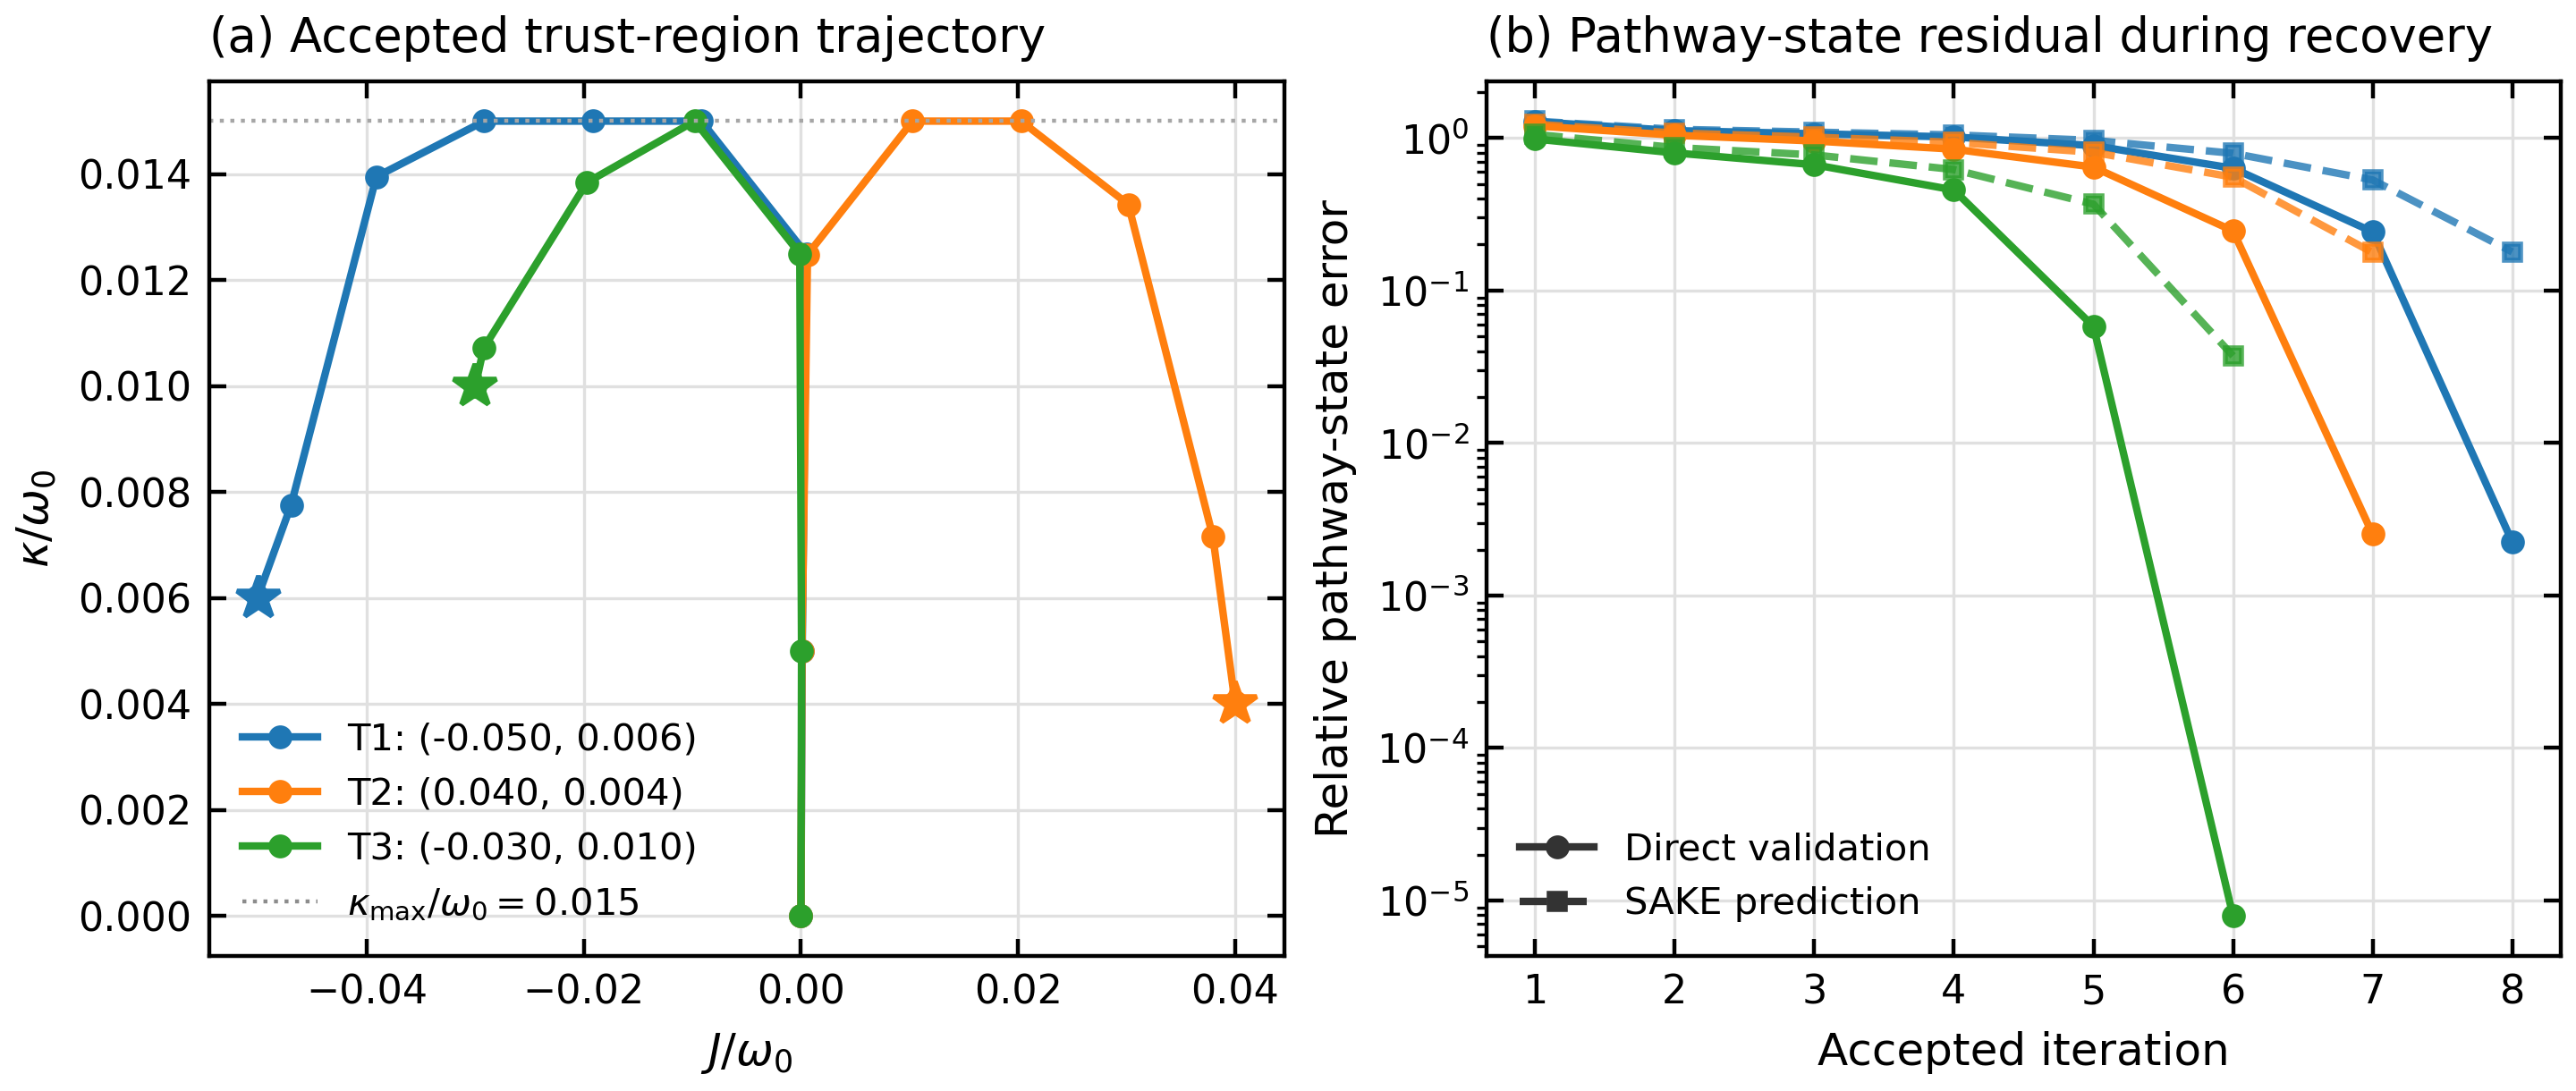

In [6]:
figure_dir = output_root / 'multi_target'
run(['python', 'plot_sake_multi_target_recovery.py', *map(str, result_dirs),
     '--omega0', str(omega0), '--normalize-controls', '--output-dir', str(figure_dir)])
display(Image(filename=str(figure_dir/'multi_target_recovery_normalized.png'), width=1000))

## Final pathway mixing

The stable mechanistic object is the global initial-to-recovered projection stored as accumulated_transport. The separately stored product of local projected maps is a closure diagnostic because finite projected pathway spaces are not exactly transitive.

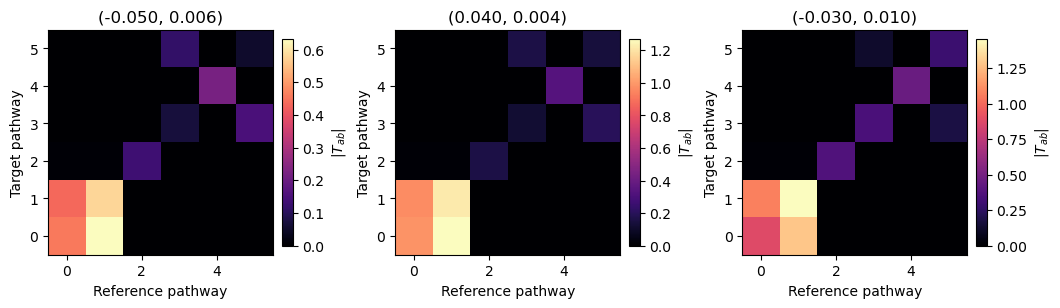

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(10.5, 3.0), constrained_layout=True)
for ax, target, path in zip(axes, targets, result_dirs):
    with np.load(path/'accumulated_transport.npz') as archive:
        transport = archive['accumulated_transport']
    image = ax.imshow(np.abs(transport), origin='lower', cmap='magma', aspect='equal')
    ax.set_title(f"({target['J']/omega0:.3f}, {target['kappa']/omega0:.3f})")
    ax.set_xlabel('Reference pathway'); ax.set_ylabel('Target pathway')
    fig.colorbar(image, ax=ax, fraction=0.046, pad=0.04, label=r'$|T_{ab}|$')
plt.show()

## Interpretation

All three synthetic targets are recovered from the uncoupled reference. The negative-$J$ target follows a pronounced $J$--$\kappa$ correlation valley and requires the largest number of direct checks. The final matrices contain substantial off-diagonal weight, so parameter recovery also provides a pathway-resolved description of the target response.